# Resume_NER — Rule-Based vs ML-Based vs Hybrid Evaluation

This notebook trains and compares three approaches on the **same held-out, manually curated phrase benchmark**:
1. **Rule-based** — canonical skill lexicon and alias matching.
2. **ML-based** — character n-gram TF-IDF + Logistic Regression phrase classifier.
3. **Hybrid** — positive when either the rule-based or ML model identifies a skill-related phrase.

Metrics reported: accuracy, precision, recall, F1, confusion matrices, and classification reports. It also demonstrates alias resolution and the hybrid merge. The included benchmark is a small, curated engineering benchmark for reproducibility, not a representative production corpus. These are **phrase-level skill-relatedness metrics**, not span-level NER metrics and not resume-to-job ranking metrics. Replace it with a consented, independently labelled benchmark before making research claims. No resumes or job descriptions are generated.

In [1]:
from pathlib import Path
import re, json
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

NOTEBOOK_DIR = Path.cwd()
DATA_CANDIDATES = [NOTEBOOK_DIR / "backend/data/skill_phrase_benchmark.csv", NOTEBOOK_DIR / "../backend/data/skill_phrase_benchmark.csv", NOTEBOOK_DIR / "../../backend/data/skill_phrase_benchmark.csv"]
DATA_PATH = next((p.resolve() for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Could not find backend/data/skill_phrase_benchmark.csv. Open this notebook from the project root or notebooks folder.")
df = pd.read_csv(DATA_PATH).dropna(subset=["phrase", "label"]).drop_duplicates()
df["label"] = df["label"].str.upper().str.strip()
df = df[df.label.isin(["SKILL", "OTHER"])].reset_index(drop=True)
print(f"Loaded {len(df)} curated phrases from {DATA_PATH}")
print(df.label.value_counts())
df.head(10)

Loaded 115 curated phrases from /mnt/data/work/Resume_NER_ATS/backend/data/skill_phrase_benchmark.csv
label
OTHER    60
SKILL    55
Name: count, dtype: int64


,phrase,label
0,Built Python scripts to automate data cleaning,SKILL
1,Developed REST APIs with FastAPI,SKILL
2,Wrote SQL joins for relational databases,SKILL
3,Used Git and GitHub for source control,SKILL
4,Applied object-oriented programming in coursework,SKILL
5,Implemented exception handling and input valid...,SKILL
6,Practiced data structures and algorithms in C++,SKILL
7,Created unit tests using pytest,SKILL
8,Used Docker to package a backend service,SKILL
9,Built a small Flask web application,SKILL


## 1. Shared benchmark split
All three models are evaluated on the same stratified held-out rows. This keeps the comparison aligned and prevents evaluating each model on a different sample.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    df["phrase"], df["label"], test_size=0.25, random_state=42, stratify=df["label"]
)
print("Train rows:", len(X_train), "| Test rows:", len(X_test))
print("Held-out label distribution:")
print(y_test.value_counts())

Train rows: 86 | Test rows: 29
Held-out label distribution:
label
OTHER    15
SKILL    14
Name: count, dtype: int64


## 2. Rule-based model
A deterministic lexicon matcher detects canonical skills and aliases. It is transparent and fast, but can produce false positives when a resume/phrase mentions a skill only to deny experience with it.

In [3]:
ALIASES = {
    "python": ["python3"], "javascript": ["js", "ecmascript"], "typescript": ["ts"],
    "react": ["reactjs", "react.js"], "node.js": ["nodejs", "node"], "fastapi": ["fast api"],
    "machine learning": ["ml"], "deep learning": ["dl"], "natural language processing": ["nlp"],
    "large language models": ["llm", "llms"], "sql": ["structured query language"],
    "postgresql": ["postgres", "psql"], "amazon web services": ["aws"],
    "google cloud": ["gcp", "google cloud platform"], "scikit-learn": ["sklearn"],
    "pytorch": ["torch"], "tensorflow": ["tf"], "rest api": ["restful api", "rest apis", "restful apis", "representational state transfer"],
    "api": ["application programming interface", "application programming interfaces"], "data structures and algorithms": ["dsa"],
    "retrieval augmented generation": ["rag"], "vector database": ["vector db", "vectordb"],
    "kubernetes": ["k8s"], "named entity recognition": ["ner"], "pandas": ["python pandas"],
    "numpy": ["np"], "computer vision": ["cv"], "power bi": ["powerbi"],
    "object-oriented programming": ["oop", "object oriented programming"], "git": ["git version control"],
    "github": ["git hub"], "relational databases": ["relational database", "rdbms"],
    "data structures": ["data structure"], "algorithms": ["algorithm"], "problem solving": ["problem-solving"],
    "exception handling": [], "fastapi": ["fast api"], "flask": [], "django": [], "pytest": [],
    "docker": [], "sqlite": [], "mysql": [], "http": [], "json": [], "postman": [], "unit testing": ["unit tests"]
}
ALIASES_FLAT = sorted({alias.lower() for canonical, aliases in ALIASES.items() for alias in [canonical, *aliases]}, key=len, reverse=True)
def rule_predict(phrase):
    phrase = str(phrase).lower()
    negation = re.compile(r"\b(?:no|not|never|without|lack\w*|does not|do not|did not|has not|have not|not yet|haven't|hasn't|isn't|aren't)\b", re.I)
    for term in ALIASES_FLAT:
        for match in re.finditer(r"(?<![a-z0-9+#.])" + re.escape(term) + r"(?![a-z0-9+#.])", phrase):
            prefix = phrase[:match.start()]
            contrasts = list(re.finditer(r"\b(?:but|however|although)\b", prefix))
            if contrasts:
                prefix = prefix[contrasts[-1].end():]
            if not negation.search(prefix):
                return "SKILL"
    return "OTHER"
rule_pred = [rule_predict(x) for x in X_test]
print(classification_report(y_test, rule_pred, labels=["OTHER", "SKILL"], zero_division=0))

              precision    recall  f1-score   support

       OTHER       0.81      0.87      0.84        15
       SKILL       0.85      0.79      0.81        14

    accuracy                           0.83        29
   macro avg       0.83      0.83      0.83        29
weighted avg       0.83      0.83      0.83        29



## 3. ML-based model
The ML-only model sees phrase text and predicts `SKILL` or `OTHER`. It does not use the rule model's output. The character n-gram features help tolerate punctuation, spelling variants, and phrase structure.

In [4]:
ml_model = Pipeline([
    ("tfidf", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=1, sublinear_tf=True)),
    ("classifier", LogisticRegression(max_iter=1500, class_weight="balanced", random_state=42))
])
ml_model.fit(X_train, y_train)
ml_pred = ml_model.predict(X_test)
ml_prob = ml_model.predict_proba(X_test)[:, list(ml_model.classes_).index("SKILL")]
print(classification_report(y_test, ml_pred, labels=["OTHER", "SKILL"], zero_division=0))

              precision    recall  f1-score   support

       OTHER       0.75      0.80      0.77        15
       SKILL       0.77      0.71      0.74        14

    accuracy                           0.76        29
   macro avg       0.76      0.76      0.76        29
weighted avg       0.76      0.76      0.76        29



## 4. Hybrid model
The hybrid combines both signals. This intentionally favours recall: if the rules identify a known skill or the ML model identifies a skill-related phrase, the hybrid marks the phrase as skill-related. It can improve recall but may also inherit false positives from either component.

In [5]:
hybrid_pred = ["SKILL" if (r == "SKILL" or m == "SKILL") else "OTHER" for r, m in zip(rule_pred, ml_pred)]
print(classification_report(y_test, hybrid_pred, labels=["OTHER", "SKILL"], zero_division=0))

              precision    recall  f1-score   support

       OTHER       0.91      0.67      0.77        15
       SKILL       0.72      0.93      0.81        14

    accuracy                           0.79        29
   macro avg       0.82      0.80      0.79        29
weighted avg       0.82      0.79      0.79        29



## 5. Metrics comparison

,Accuracy,Precision (SKILL),Recall (SKILL),F1 (SKILL)
Model,,,,
Rule-Based,0.828,0.846,0.786,0.815
ML-Based,0.759,0.769,0.714,0.741
Hybrid,0.793,0.722,0.929,0.812


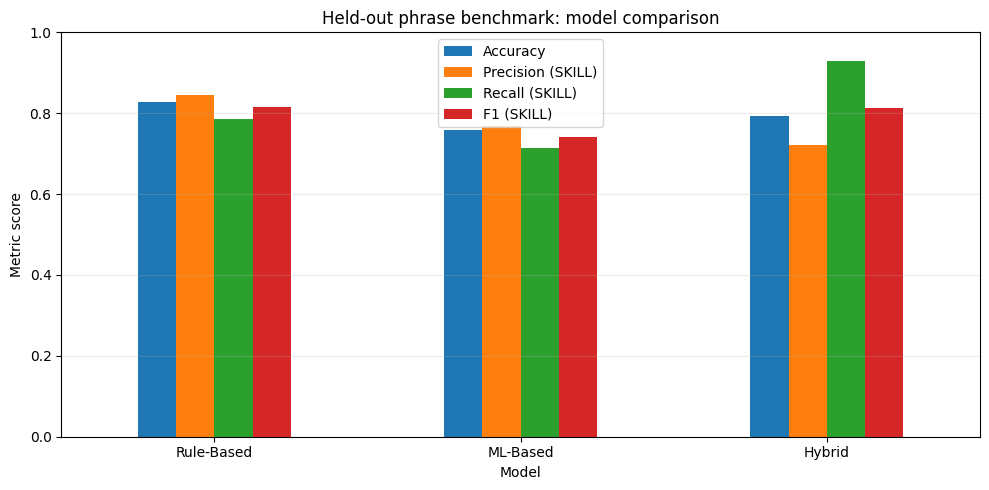

In [6]:
predictions = {"Rule-Based": rule_pred, "ML-Based": list(ml_pred), "Hybrid": hybrid_pred}
rows = []
for name, pred in predictions.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (SKILL)": precision_score(y_test, pred, pos_label="SKILL", zero_division=0),
        "Recall (SKILL)": recall_score(y_test, pred, pos_label="SKILL", zero_division=0),
        "F1 (SKILL)": f1_score(y_test, pred, pos_label="SKILL", zero_division=0),
    })
metrics_df = pd.DataFrame(rows).set_index("Model").round(3)
display(metrics_df)
ax = metrics_df.plot(kind="bar", ylim=(0, 1), figsize=(10, 5), rot=0, title="Held-out phrase benchmark: model comparison")
ax.set_ylabel("Metric score")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### Reading the benchmark results

On the included fixed split (29 held-out phrases), the current run produced approximately:
- **Rule-Based:** accuracy 0.828, precision 0.846, recall 0.786, F1 0.815.
- **ML-Based:** accuracy 0.759, precision 0.769, recall 0.714, F1 0.741.
- **Hybrid:** accuracy 0.793, precision 0.722, recall 0.929, F1 0.812.

In this small benchmark, the hybrid improves recall by combining signals, at the cost of additional false positives; the rule-based baseline has the highest accuracy and precision. These values are tied to the included curated phrases and fixed split and should not be presented as general production performance.

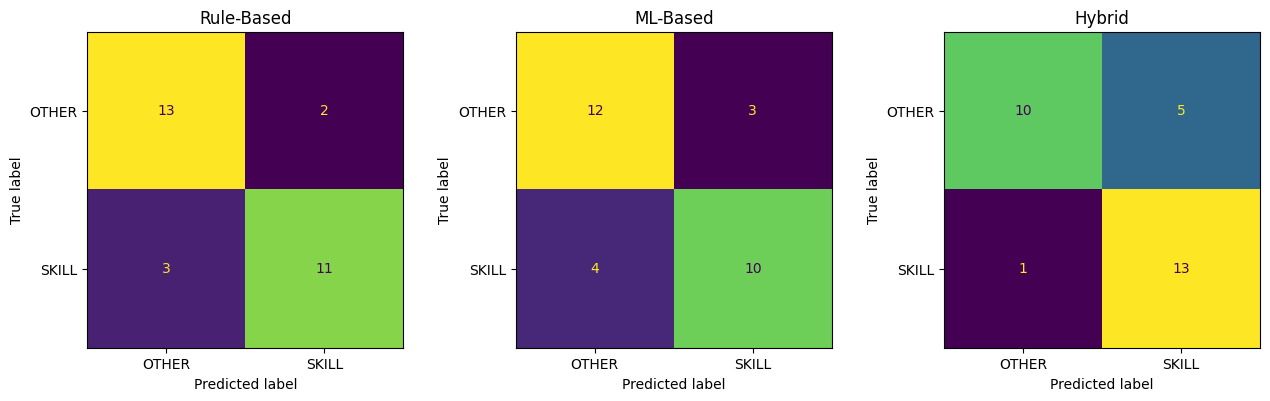

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred, labels=["OTHER", "SKILL"])
    ConfusionMatrixDisplay(cm, display_labels=["OTHER", "SKILL"]).plot(ax=ax, colorbar=False, values_format="d")
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 6. Resolution / canonicalization example
The full application uses an alias resolver after extraction. For example, `sklearn` resolves to `scikit-learn`, `RESTful API` resolves to `representational state transfer`, and duplicate aliases are collapsed to one canonical skill. This keeps downstream job matching consistent.

In [8]:
CANON = {alias.lower(): canonical for canonical, aliases in ALIASES.items() for alias in [canonical, *aliases]}
def normalize_terms(terms):
    return sorted({CANON.get(str(term).strip().lower(), str(term).strip().lower()) for term in terms if str(term).strip()})
examples = {
    "raw_terms": ["sklearn", "scikit-learn", "RESTful API", "REST APIs", "rest api", "python3", "Python"],
    "normalized_terms": normalize_terms(["sklearn", "scikit-learn", "RESTful API", "REST APIs", "rest api", "python3", "Python"])
}
examples

{'raw_terms': ['sklearn',
  'scikit-learn',
  'RESTful API',
  'REST APIs',
  'rest api',
  'python3',
  'Python'],
 'normalized_terms': ['python', 'rest api', 'scikit-learn']}

## 7. Inspect held-out disagreements
Use this to see where the models disagree. This is especially useful for reviewing false positives and false negatives before trusting a model in a real workflow.

In [9]:
comparison = pd.DataFrame({"phrase": list(X_test), "actual": list(y_test), "rule_based": rule_pred, "ml_based": list(ml_pred), "hybrid": hybrid_pred})
display(comparison[(comparison.rule_based != comparison.ml_based) | (comparison.hybrid != comparison.ml_based)].head(40))

,phrase,actual,rule_based,ml_based,hybrid
3,Used PowerPoint to present research findings,OTHER,OTHER,SKILL,SKILL
5,Python is listed as a future learning goal,OTHER,SKILL,OTHER,SKILL
10,The applicant wants to learn machine learning,OTHER,SKILL,OTHER,SKILL
11,Implemented semantic similarity with cosine si...,SKILL,OTHER,SKILL,SKILL
13,Resume includes education and contact information,OTHER,OTHER,SKILL,SKILL
17,Developed REST APIs with FastAPI,SKILL,SKILL,OTHER,SKILL
19,Collaborated through pull requests on GitHub,SKILL,SKILL,OTHER,SKILL
23,Has not built a web application,OTHER,OTHER,SKILL,SKILL
27,Built a natural language understanding pipeline,SKILL,OTHER,SKILL,SKILL
28,Handled JSON payloads in an API request,SKILL,SKILL,OTHER,SKILL


## 8. Save metrics and trained model
The API currently trains its lightweight phrase classifier from the included benchmark at runtime, so the web app does not depend on running this notebook first. Running this cell saves the notebook-trained model and the benchmark metrics for reproducibility.

In [10]:
PROJECT_ROOT = DATA_PATH.parents[2]
MODEL_DIR = PROJECT_ROOT / "backend" / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
import joblib
joblib.dump(ml_model, MODEL_DIR / "skill_phrase_model.joblib")
metrics_path = PROJECT_ROOT / "backend" / "models" / "phrase_benchmark_metrics.csv"
metrics_df.to_csv(metrics_path)
print("Saved model:", MODEL_DIR / "skill_phrase_model.joblib")
print("Saved metrics:", metrics_path)
print("Reminder: benchmark results are small-sample phrase classification metrics, not production NER or hiring validation.")

Saved model: /mnt/data/work/Resume_NER_ATS/backend/models/skill_phrase_model.joblib
Saved metrics: /mnt/data/work/Resume_NER_ATS/backend/models/phrase_benchmark_metrics.csv
Reminder: benchmark results are small-sample phrase classification metrics, not production NER or hiring validation.


## Interpretation and limitations
- The benchmark is curated and small; scores are useful for a reproducible demonstration, not evidence of real-world generalization.
- Phrase classification metrics do not measure exact entity-span boundaries.
- Hybrid scoring in the web application additionally uses resume/JD skill coverage, TF-IDF text similarity, experience/project evidence, and parsing quality. These ranking scores are not the same as the phrase-level metrics above.
- Do not use this system to make automatic hiring decisions. Keep protected attributes out of scoring and require human review.